# Predicción del rendimiento académico: optimización de hiperparámetros y comparación de optimizadores

**Optimización e Inteligencia Artificial, UNAL**

**Integrantes:** Juan José Munera Pulgarín, María Cristina Narváez, Sebastián Rodríguez Suarez, Santiago Vanegas Vasquez, Nicolás Ruiz Blandón

**Problema:** regresión del `Exam_Score` (0–100) con el dataset *Student Performance Factors* (Kaggle).

**Optimización involucrada:**
- **Enfoque A, hiperparámetros:** minimizar el MSE de validación cruzada respecto a los hiperparámetros $\theta$, $\min_\theta \; \text{MSE}_{CV}(\theta)$, optimizando exclusivamente un perceptrón multicapa (MLP) con Grid Search, Random Search, optimización bayesiana, algoritmo genético y PSO.
- **Enfoque B, entrenamiento:** minimizar el MSE respecto a los pesos $w$ del MLP, comparando SGD, SGD con momentum, RMSprop y Adam.

## 0. Configuración

Instalamos e importamos las librerías. Instalamos e importamos las librerías necesarias para el MLP, el preprocesamiento y los cinco métodos de optimización.

In [22]:
#Instalamos las librerías que se usaron en clase (en Colab hace falta; en el venv local ya están)
# - scikit-optimize: optimización bayesiana (BayesSearchCV)
# - pygad: algoritmo genético
# - pymetaheuristic: PSO
# - kagglehub: descarga del dataset desde Kaggle
%pip install -q scikit-optimize pygad pymetaheuristic kagglehub matplotlib seaborn torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [4]:
#Importacion de librerias
import os
# Silencia los avisos también en los procesos paralelos de joblib (heredan esta variable)
os.environ["PYTHONWARNINGS"] = "ignore"
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Herramientas de sklearn: partición de datos, validación cruzada y búsquedas de hiperparámetros
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
#Preprocesamiento: imputación, codificación de categóricas y escalado dentro de un pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
#Modelo de regresión
from sklearn.neural_network import MLPRegressor
#Métricas de evaluación para regresión
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
#Distribuciones para el muestreo de Random Search
from scipy.stats import loguniform

from skopt import BayesSearchCV                 # Clase 1 - notebooks 4 y 5
from skopt.space import Real, Integer, Categorical
import pygad                                    # Clase 3 - notebook 14 (AG para hiperparámetros)
import pymetaheuristic                          # Clase 3 - notebooks 15 y 16 (PSO)

warnings.filterwarnings("ignore")
#Fijamos la semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Carga de datos

El dataset *Student Performance Factors* tiene un registro por estudiante con factores académicos (horas de estudio, asistencia, tutorías, puntajes previos), familiares (ingresos, nivel educativo de los padres, involucramiento) y personales (sueño, motivación, actividad física). La variable a estimar es `Exam_Score`, el puntaje del examen en escala de 0 a 100.

In [5]:
#Carga de datos - dataset Student Performance Factors (Kaggle)
# Opción 1: descarga directa desde Kaggle con kagglehub
# Opción 2: subir StudentPerformanceFactors.csv a la misma carpeta del notebook
import os
CSV = "StudentPerformanceFactors.csv"
if not os.path.exists(CSV):
    import kagglehub
    path = kagglehub.dataset_download("lainguyn123/student-performance-factors")
    CSV = os.path.join(path, "StudentPerformanceFactors.csv")

#Organizamos los datos en un DataFrame de pandas
df = pd.read_csv(CSV)
#Número de registros (estudiantes) y de columnas (factores + Exam_Score)
print(df.shape)
df.head()

100%|██████████| 93.9k/93.9k [00:00<00:00, 514kB/s]

Extracting files...


(6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [6]:
#Tipos de dato de cada columna y cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [8]:
#Estadísticas descriptivas de las variables numéricas (media, desviación, mínimo, máximo, cuartiles)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


## 2. Análisis exploratorio

Antes de modelar revisamos la calidad de los datos (faltantes y valores fuera de rango) y cómo se relacionan las variables con el puntaje. Esto nos da una idea de qué tan difícil es el problema: si la relación es casi lineal, un modelo simple como MLP debería competir con modelos más complejos.

In [9]:
#Revisamos la calidad de los datos antes de modelar
#Columnas con valores faltantes
print("Valores faltantes por columna:")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nFilas con algún faltante: {df.isna().any(axis=1).mean():.2%}")
#Valores imposibles: asistencia negativa o puntajes fuera de la escala 0-100
print(f"Attendance < 0: {(df['Attendance'] < 0).sum()}")
print(f"Exam_Score fuera de [0, 100]: {((df['Exam_Score'] < 0) | (df['Exam_Score'] > 100)).sum()}")

Valores faltantes por columna:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Filas con algún faltante: 3.47%
Attendance < 0: 0
Exam_Score fuera de [0, 100]: 1


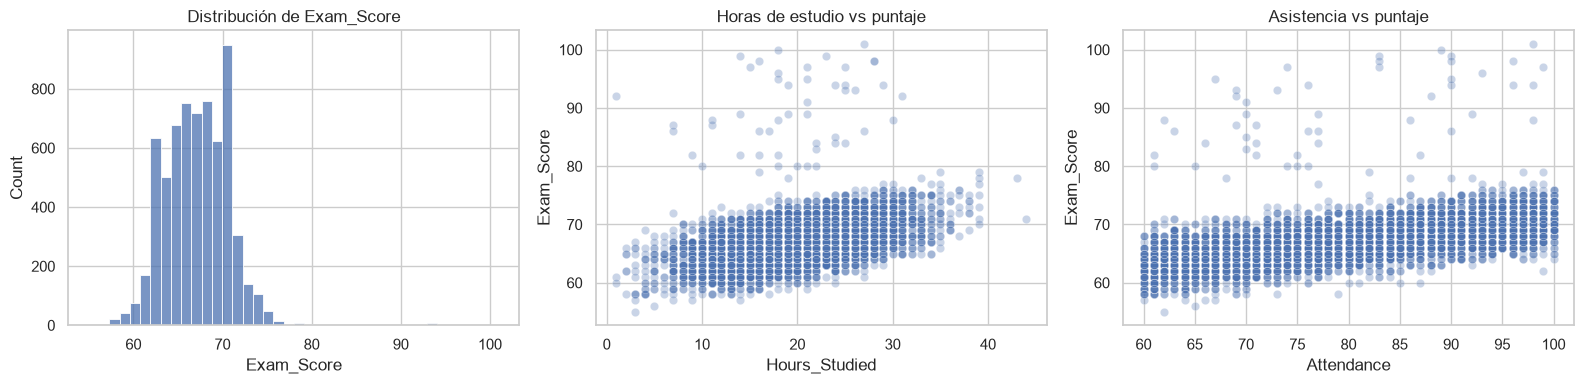

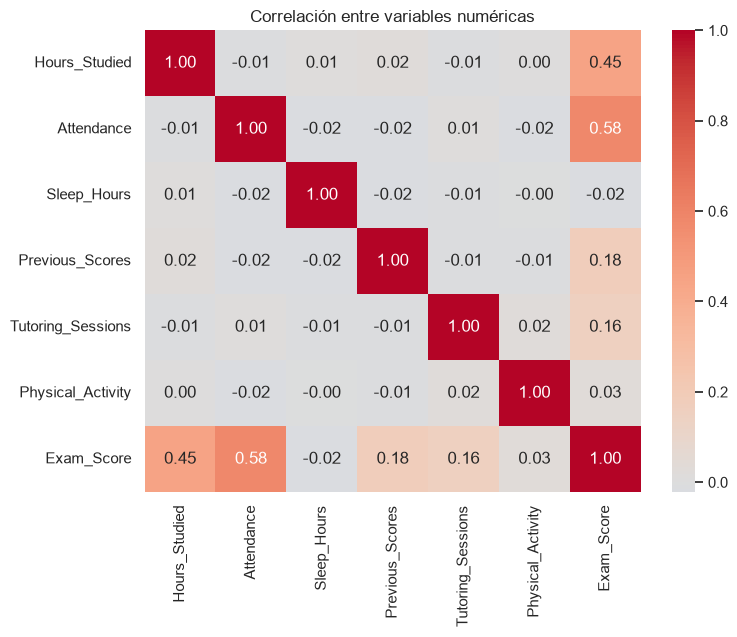

In [10]:
#Visualizamos la variable objetivo y su relación con los dos factores más intuitivos
num_cols_all = df.select_dtypes(include="number").columns
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Exam_Score"], bins=40, ax=axes[0]).set_title("Distribución de Exam_Score")
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", alpha=.3, ax=axes[1]).set_title("Horas de estudio vs puntaje")
sns.scatterplot(data=df, x="Attendance", y="Exam_Score", alpha=.3, ax=axes[2]).set_title("Asistencia vs puntaje")
plt.tight_layout(); plt.show()

#Matriz de correlación: qué variables numéricas se relacionan linealmente con el puntaje
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols_all].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas"); plt.show()

## 3. Limpieza

- Se eliminan los registros con `Attendance` negativo y con `Exam_Score` fuera de [0, 100].
- Los faltantes (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) se imputan con la **moda** dentro del pipeline, ajustada solo con el conjunto de entrenamiento para evitar fuga de información.

In [11]:
#Eliminamos los registros con valores imposibles (asistencia negativa o puntaje fuera de [0, 100])
n0 = len(df)
df = df[(df["Attendance"] >= 0) & (df["Exam_Score"].between(0, 100))].reset_index(drop=True)
print(f"Registros eliminados: {n0 - len(df)}  ->  quedan {len(df)}")

Registros eliminados: 1  ->  quedan 6606


## 4. Codificación, escalado y partición

Las variables son de tres tipos y cada una se trata distinto:

* **Numéricas** (horas de estudio, asistencia, sueño, etc.): se estandarizan para que todas tengan la misma escala. Esto es importante para MLP y sobre todo para la MLP, que se entrena con descenso de gradiente.
* **Ordinales** (Low/Medium/High, Near/Moderate/Far, etc.): se codifican como enteros respetando su orden.
* **Nominales o binarias** (género, tipo de colegio, acceso a internet, etc.): se codifican con *one-hot*.

Todo se hace dentro de un `Pipeline`, de modo que en la validación cruzada el preprocesamiento se ajusta únicamente con los folds de entrenamiento.

In [12]:
#Separamos las variables de entrada (X) del valor a estimar (y)
TARGET = "Exam_Score"
X = df.drop(columns=TARGET)   #Muestras
y = df[TARGET].values         #Valor a estimar

# Variables categóricas ordinales (tienen un orden natural): se codifican como 0, 1, 2 respetando ese orden
ordinal_map = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
}
ord_cols = list(ordinal_map)
num_cols = X.select_dtypes(include="number").columns.tolist()
nom_cols = [c for c in X.columns if c not in ord_cols + num_cols]   # binarias / nominales
print("Numéricas:", num_cols, "\nOrdinales:", ord_cols, "\nNominales:", nom_cols)

#Preprocesamiento por tipo de variable:
# - numéricas: imputación con la mediana + estandarización
# - ordinales: imputación con la moda + codificación ordinal + estandarización
# - nominales/binarias: imputación con la moda + one-hot (una sola columna si es binaria)
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OrdinalEncoder(categories=[ordinal_map[c] for c in ord_cols])),
                      ("sc", StandardScaler())]), ord_cols),
    ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), nom_cols),
])

#Seleccionamos 80% de muestras para entrenamiento y 20% para prueba
#El conjunto de prueba no se toca hasta evaluar los modelos finales
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")

Numéricas: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity'] 
Ordinales: ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Parental_Education_Level', 'Distance_from_Home'] 
Nominales: ['Extracurricular_Activities', 'Internet_Access', 'School_Type', 'Learning_Disabilities', 'Gender']
Train: (5284, 19)  Test: (1322, 19)


## 5. Línea base del MLP (hiperparámetros por defecto)

Entrenamos el MLP con los hiperparámetros por defecto de sklearn. Este es el punto de referencia: la optimización solo vale la pena si mejora claramente estos resultados.

Usamos el RMSE como métrica principal porque está en las mismas unidades del puntaje.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

def evaluate(model, name, method, t=np.nan, n_evals=np.nan, cv_rmse=np.nan):
    pred = model.predict(X_test)
    return {"Modelo": name, "Método": method, "RMSE_CV": cv_rmse,
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
            "MAE_test": mean_absolute_error(y_test, pred), "R2_test": r2_score(y_test, pred),
            "Tiempo_s": t, "Evaluaciones": n_evals}

base_models = {"MLP": MLPRegressor(random_state=SEED, max_iter=500)}
results, best_models = [], {}
for name, model in base_models.items():
    pipe = make_pipe(model); t0 = time.time()
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    pipe.fit(X_train, y_train)
    results.append(evaluate(pipe, name, "Por defecto", time.time() - t0, 1, cv_rmse))
    best_models[(name, "Por defecto")] = pipe
pd.DataFrame(results)

,Modelo,Método,RMSE_CV,RMSE_test,MAE_test,R2_test,Tiempo_s,Evaluaciones
0,MLP,Por defecto,2.355861,1.826953,0.93339,0.747603,7.205406,1


## 6. Enfoque A: optimización de hiperparámetros del MLP

Se comparan Grid Search, Random Search, optimización bayesiana, algoritmo genético y PSO con la misma validación cruzada. Se optimizan la cantidad de capas y neuronas mediante arch, además de la función de activación, el número de épocas, la regularización y la tasa de aprendizaje.

Definimos espacios de búsqueda exclusivos para el MLP. arch codifica el número de capas y las neuronas de cada capa: por ejemplo, 64-32-16 representa tres capas ocultas. Grid Search usa combinaciones fijas; Random Search y la búsqueda bayesiana muestrean rangos; AG y PSO convierten vectores reales en hiperparámetros válidos.

In [14]:
N_EVALS = 30

class MLPArch(MLPRegressor):
    def __init__(self, arch="64", alpha=1e-4, learning_rate_init=1e-3, max_iter=500, activation="relu", early_stopping=True, random_state=None):
        self.arch = arch
        super().__init__(alpha=alpha, learning_rate_init=learning_rate_init, max_iter=max_iter, activation=activation, early_stopping=early_stopping, random_state=random_state)
    def fit(self, X, y):
        self.hidden_layer_sizes = tuple(int(n) for n in self.arch.split("-"))
        return super().fit(X, y)

ARCHS = ["16", "32", "64", "128", "32-16", "64-32", "128-64", "64-32-16", "128-64-32"]
model_ctor = {"MLP": lambda **p: MLPArch(random_state=SEED, **p)}
grids = {"MLP": {"model__arch": ["32", "64", "64-32", "64-32-16"], "model__activation": ["relu", "tanh", "logistic"], "model__max_iter": [200, 500, 1000], "model__alpha": [1e-4, 1e-2, 1], "model__learning_rate_init": [1e-3, 1e-2]}}
dists = {"MLP": {"model__arch": ARCHS, "model__activation": ["relu", "tanh", "logistic"], "model__max_iter": [200, 300, 500, 750, 1000], "model__alpha": loguniform(1e-5, 10), "model__learning_rate_init": loguniform(1e-4, 1e-1)}}
bayes_spaces = {"MLP": {"model__arch": Categorical(ARCHS), "model__activation": Categorical(["relu", "tanh", "logistic"]), "model__max_iter": Integer(200, 1000), "model__alpha": Real(1e-5, 10, prior="log-uniform"), "model__learning_rate_init": Real(1e-4, 1e-1, prior="log-uniform")}}
bounds = {"MLP": [(0, len(ARCHS) - 1e-6), (-5, 1), (-4, -1), (0, 2), (200, 1000)]}
def decode(name, v):
    return {"arch": ARCHS[int(v[0])], "alpha": 10 ** v[1], "learning_rate_init": 10 ** v[2], "activation": ["relu", "tanh", "logistic"][int(v[3])], "max_iter": int(round(v[4]))}
def cv_rmse(name, params):
    return -cross_val_score(make_pipe(model_ctor[name](**params)), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()

Ejecutamos las búsquedas únicamente para el MLP. Cada evaluación entrena el modelo en los cinco folds; al terminar, la mejor configuración se reentrena con todo el conjunto de entrenamiento y se evalúa en prueba.

In [15]:
histories = {}; best_params = {}
def register(name, method, estimator, t, hist, best_cv, params):
    histories[(name, method)] = np.asarray(hist); best_params[(name, method)] = params; best_models[(name, method)] = estimator
    results.append(evaluate(estimator, name, method, t, len(hist), best_cv)); print(f"{method:10s} RMSE_CV={best_cv:.4f}  evals={len(hist):3d}  ({t:.1f}s)")
def run_sklearn_search(name, method, search):
    t0 = time.time(); search.fit(X_train, y_train)
    register(name, method, search.best_estimator_, time.time()-t0, -search.cv_results_["mean_test_score"], -search.best_score_, search.best_params_)
def run_metaheuristic(name, method):
    hist, cache = [], {}
    def f(v):
        params = decode(name, v); key = str(params)
        if key not in cache: cache[key] = cv_rmse(name, params)
        hist.append(cache[key]); return cache[key]
    t0 = time.time()
    if method == "AG":
        ga = pygad.GA(num_generations=4, sol_per_pop=6, num_parents_mating=3, num_genes=len(bounds[name]), gene_space=[{"low":lo,"high":hi} for lo,hi in bounds[name]], fitness_func=lambda ga,sol,idx:-f(sol), parent_selection_type="tournament", crossover_type="uniform", mutation_type="random", keep_parents=1, random_seed=SEED); ga.run(); best_v = ga.best_solution()[0]
    else:
        pso = pymetaheuristic.optimize(algorithm="pso", target_function=f, min_values=[lo for lo,_ in bounds[name]], max_values=[hi for _,hi in bounds[name]], max_steps=4, swarm_size=6, w=0.9, c1=2.0, c2=2.0); best_v = pso.best_position
    params = decode(name, best_v); est = make_pipe(model_ctor[name](**params)).fit(X_train, y_train); register(name, method, est, time.time()-t0, hist, min(hist), params)
for method, search in [("Grid", GridSearchCV(make_pipe(model_ctor["MLP"]()), grids["MLP"], cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)), ("Random", RandomizedSearchCV(make_pipe(model_ctor["MLP"]()), dists["MLP"], n_iter=N_EVALS, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED)), ("Bayesiana", BayesSearchCV(make_pipe(model_ctor["MLP"]()), bayes_spaces["MLP"], n_iter=N_EVALS, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED))]:
    run_sklearn_search("MLP", method, search)
run_metaheuristic("MLP", "AG"); run_metaheuristic("MLP", "PSO")

Grid       RMSE_CV=2.1144  evals=216  (259.2s)
Random     RMSE_CV=2.1476  evals= 30  (50.6s)
Bayesiana  RMSE_CV=2.1347  evals= 30  (77.0s)
AG         RMSE_CV=2.0932  evals= 30  (40.2s)
PSO        RMSE_CV=2.1037  evals= 30  (55.4s)


### 6.1 Resultados

En la tabla, `RMSE_CV` es el mejor valor de la función objetivo que encontró cada método (lo que se optimizó), mientras que `RMSE_test`, `MAE_test` y `R2_test` miden qué tan bien generaliza el modelo final a datos que nunca vio.

In [16]:
#Tabla comparativa: error de validación cruzada, métricas en prueba, tiempo y número de evaluaciones
res = pd.DataFrame(results).round(4)
res

,Modelo,Método,RMSE_CV,RMSE_test,MAE_test,R2_test,Tiempo_s,Evaluaciones
0,MLP,Por defecto,2.3559,1.8270,0.9334,0.7476,7.2054,1
1,MLP,Grid,2.1144,1.5771,0.5157,0.8119,259.1632,216
2,MLP,Random,2.1476,1.7035,0.7188,0.7806,50.5855,30
3,MLP,Bayesiana,2.1347,1.6433,0.5801,0.7958,77.0330,30
4,MLP,AG,2.0932,1.5451,0.5006,0.8195,40.2041,30
5,MLP,PSO,2.1037,1.5825,0.5114,0.8106,55.3998,30


In [17]:
#Mejores hiperparámetros encontrados por cada método para cada modelo
for k, v in best_params.items():
    print(k, v)

('MLP', 'Grid') {'model__activation': 'logistic', 'model__alpha': 1, 'model__arch': '64', 'model__learning_rate_init': 0.01, 'model__max_iter': 200}
('MLP', 'Random') {'model__activation': 'relu', 'model__alpha': np.float64(5.848333713948899), 'model__arch': '32-16', 'model__learning_rate_init': np.float64(0.001465655388622534), 'model__max_iter': 300}
('MLP', 'Bayesiana') OrderedDict({'model__activation': 'logistic', 'model__alpha': 0.1598558991826748, 'model__arch': '64-32-16', 'model__learning_rate_init': 0.0017679226616446444, 'model__max_iter': 505})
('MLP', 'AG') {'arch': '32', 'alpha': np.float64(6.59871107205407), 'learning_rate_init': np.float64(0.004895834359555105), 'activation': 'relu', 'max_iter': 941}
('MLP', 'PSO') {'arch': '16', 'alpha': 1.4134310958925749, 'learning_rate_init': 0.00783141509638603, 'activation': 'relu', 'max_iter': 1000}


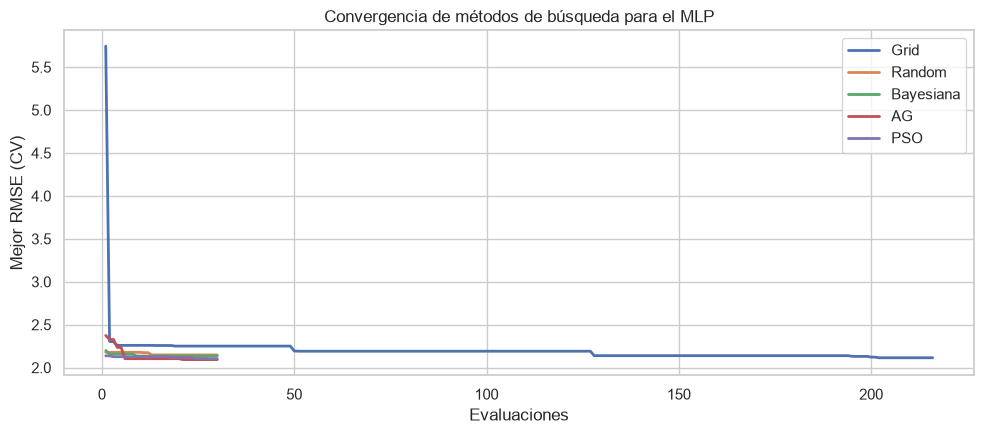

In [18]:
METHODS = ["Grid", "Random", "Bayesiana", "AG", "PSO"]
fig, ax = plt.subplots(figsize=(10, 4.5))
for method in METHODS:
    h = histories[("MLP", method)]; ax.plot(np.arange(1, len(h)+1), np.minimum.accumulate(h), label=method, lw=2)
ax.set_title("Convergencia de métodos de búsqueda para el MLP"); ax.set_xlabel("Evaluaciones"); ax.set_ylabel("Mejor RMSE (CV)"); ax.legend(); plt.tight_layout(); plt.show()

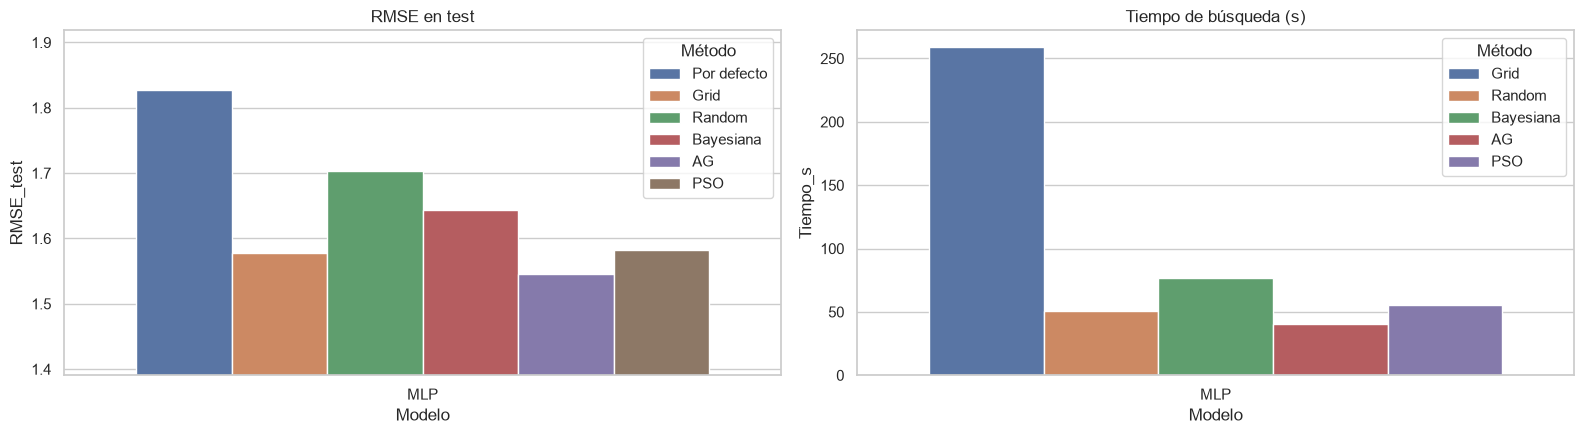

In [19]:
#Comparamos el error en prueba (izquierda) y el costo computacional de cada búsqueda (derecha)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.barplot(data=res, x="Modelo", y="RMSE_test", hue="Método", ax=axes[0]).set_title("RMSE en test")
#Ajustamos el eje y para que se noten las diferencias entre métodos
axes[0].set_ylim(res["RMSE_test"].min() * 0.9, res["RMSE_test"].max() * 1.05)
sns.barplot(data=res[res["Método"] != "Por defecto"], x="Modelo", y="Tiempo_s", hue="Método", ax=axes[1]).set_title("Tiempo de búsqueda (s)")
plt.tight_layout(); plt.show()

## 7. Enfoque B: comparación de optimizadores de entrenamiento

La misma MLP (misma arquitectura e inicialización) se entrena con los cuatro optimizadores que se compararon en la Clase 2 (notebook 10): SGD, SGD con momentum, RMSprop y Adam, todos con `lr = 0.001`. Se minimiza el MSE respecto a los pesos. En clase se usó Keras; aquí se usa PyTorch porque TensorFlow todavía no tiene versión para Python 3.14, pero los algoritmos son los mismos.

In [23]:
import torch
import torch.nn as nn
torch.manual_seed(SEED)

#Reutilizamos el mismo preprocesamiento, ajustado solo con el conjunto de entrenamiento
prep_fit = preprocess.fit(X_train)
#Convertimos los datos a tensores de PyTorch
Xtr = torch.tensor(prep_fit.transform(X_train), dtype=torch.float32)
Xte = torch.tensor(prep_fit.transform(X_test), dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
yte = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

#Definición de la red: dos capas ocultas (64 y 32 neuronas, ReLU) y una neurona de salida lineal (regresión)
def make_net():
    torch.manual_seed(SEED)          # misma inicialización para todos
    return nn.Sequential(nn.Linear(Xtr.shape[1], 64), nn.ReLU(),
                         nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

#Optimizadores a comparar, todos con la misma tasa de aprendizaje
optimizers = {
    "SGD":          lambda p: torch.optim.SGD(p, lr=1e-3),                 # descenso de gradiente estocástico
    "SGD+Momentum": lambda p: torch.optim.SGD(p, lr=1e-3, momentum=0.9),   # acumula la dirección de pasos anteriores
    "RMSprop":      lambda p: torch.optim.RMSprop(p, lr=1e-3),             # tasa adaptativa por parámetro
    "Adam":         lambda p: torch.optim.Adam(p, lr=1e-3),                # momentum + tasa adaptativa
}
EPOCHS, BATCH = 100, 64
#Función de pérdida: error cuadrático medio
loss_fn = nn.MSELoss()
curves, opt_results = {}, []

for name, make_opt in optimizers.items():
    #Inicialización
    net = make_net(); opt = make_opt(net.parameters())
    tr_hist, te_hist = [], []
    g = torch.Generator().manual_seed(SEED)   # mismo orden de mini-lotes para todos los optimizadores
    t0 = time.time()
    #Entrenamiento por mini-lotes
    for ep in range(EPOCHS):
        net.train()
        for idx in torch.randperm(len(Xtr), generator=g).split(BATCH):
            opt.zero_grad()                              # reinicia los gradientes
            loss = loss_fn(net(Xtr[idx]), ytr[idx])      # paso hacia adelante y cálculo de la pérdida
            loss.backward(); opt.step()                  # retropropagación y actualización de los pesos
        #Al final de cada época registramos la pérdida en entrenamiento y en prueba
        net.eval()
        with torch.no_grad():
            tr_hist.append(loss_fn(net(Xtr), ytr).item())
            te_hist.append(loss_fn(net(Xte), yte).item())
    curves[name] = (tr_hist, te_hist)
    #Evaluacion final en el conjunto de prueba
    with torch.no_grad():
        pred = net(Xte).numpy().ravel()
    opt_results.append({"Optimizador": name, "RMSE_test": np.sqrt(mean_squared_error(y_test, pred)),
                        "MAE_test": mean_absolute_error(y_test, pred), "R2_test": r2_score(y_test, pred),
                        "Tiempo_s": time.time() - t0})
    print(f"{name:13s} MSE test final = {te_hist[-1]:.3f}")

pd.DataFrame(opt_results).round(4)

SGD           MSE test final = 4.829
SGD+Momentum  MSE test final = 3.517
RMSprop       MSE test final = 2.889
Adam          MSE test final = 3.142


,Optimizador,RMSE_test,MAE_test,R2_test,Tiempo_s
0,SGD,2.1976,1.4891,0.6348,0.9250
1,SGD+Momentum,1.8755,0.9762,0.7340,0.8532
2,RMSprop,1.6996,0.7141,0.7816,1.0656
3,Adam,1.7726,0.8074,0.7624,1.2712


Graficamos la pérdida por época de cada optimizador (escala logarítmica). En este caso el comportamiento no es el esperado a priori: con la misma inicialización, SGD y sobre todo SGD con momentum parten de una pérdida mucho menor en la primera época, mientras que Adam empieza muy alto (MSE ≈ 3000) y desciende de forma suave pero lenta. SGD sin momentum es el más ruidoso, con picos frecuentes durante todo el entrenamiento.

In [ ]:
#Curvas de aprendizaje de cada optimizador (escala logarítmica para ver mejor las diferencias)
#Si la pérdida de entrenamiento sigue bajando y la de prueba sube, hay sobreajuste
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, (tr, te) in curves.items():
    axes[0].plot(tr, label=name, lw=2); axes[1].plot(te, label=name, lw=2)
for ax, t in zip(axes, ["Pérdida de entrenamiento (MSE)", "Pérdida en test (MSE)"]):
    ax.set_yscale("log"); ax.set_xlabel("Época"); ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

## 8. Análisis de sesgo por grupos

Retomando la sección ética de la primera entrega: ¿el mejor modelo comete errores parecidos en los distintos grupos?

In [ ]:
#Escogemos la configuración (modelo + método) con menor RMSE en prueba
best_row = res[res["Método"] != "Por defecto"].sort_values("RMSE_test").iloc[0]
print("Mejor configuración:", best_row["Modelo"], "-", best_row["Método"])
best_model = best_models[(best_row["Modelo"], best_row["Método"])]

#Error absoluto de cada estudiante del conjunto de prueba
err = X_test.copy()
err["abs_err"] = np.abs(y_test - best_model.predict(X_test))
#Error medio y número de estudiantes por grupo de cada variable sensible
for col in ["Family_Income", "Gender", "Learning_Disabilities", "Internet_Access", "School_Type"]:
    print(err.groupby(col)["abs_err"].agg(["mean", "count"]).round(3), "\n")

## 9. Conclusiones

**Optimización de hiperparámetros del MLP (enfoque A)**

- Se estudia exclusivamente un MLP y se comparan cinco métodos con la misma métrica RMSE_CV y validación cruzada.
- El espacio de búsqueda incluye número de capas y neuronas por capa mediante arch, función de activación, número de épocas, regularización alpha y tasa de aprendizaje.
- La tabla y las curvas identifican el método que alcanza el menor RMSE_CV y la configuración ganadora se evalúa sobre el conjunto de prueba.

**Optimizadores de entrenamiento (enfoque B)**

- Se comparan SGD, SGD con momentum, RMSprop y Adam usando la misma arquitectura, inicialización y tasa de aprendizaje.

**Sesgo por grupos**

- El análisis se realiza sobre la mejor configuración del MLP encontrada en el enfoque A y reporta el error absoluto medio por grupo.